In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [4]:
work_folder = 'edge_spen'
saving_folder = 'l1'

os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [6]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

In [7]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))
from ppo_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_ants = PPO_ants( env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)
        

In [8]:
weights = []
for saving_folder in ['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']:
    ppo_ants.setup_networks()
    ppo_ants.load_weights(saving_folder + '/weights')
    # similarity evaluation
    weights.append( torch.nn.utils.parameters_to_vector(ppo_ants.actor.state_dict().values()).numpy() )

In [9]:
#weights.append(np.random.normal(np.mean(weights, axis=0), np.std(weights, axis=0), size=weights[0].shape))
weights = np.array(weights)

In [10]:
diff_w = np.linalg.norm(weights[:,None,:] - weights[None,:,:], axis=-1)

Text(0.5, 1.0, 'log-Pairwise L2 Distance between Policy Weights')

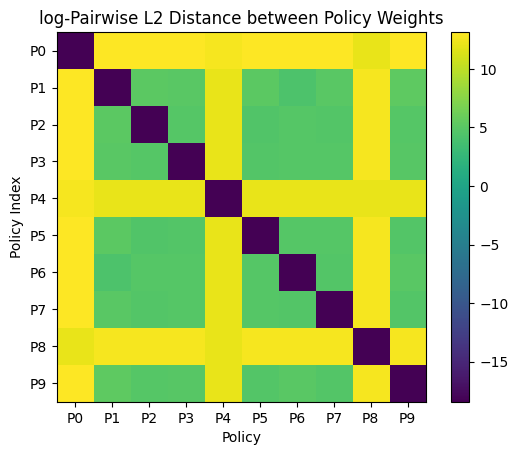

In [ ]:
plt.imshow(np.log(diff_w + 1e-8), cmap='viridis')
plt.colorbar()
plt.xticks(ticks=range(len(weights)), labels=[f'P{i}' for i in range(len(weights))])
plt.yticks(ticks=range(len(weights)), labels=[f'P{i}' for i in range(len(weights))])
plt.xlabel('Policy Index')
plt.ylabel('Policy Index')
plt.title('log-Pairwise L2 Distance between Policy Weights')

In [ ]:
save = False
load = True

if save:  
    action_list = []
    for saving_folder in ['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']:
        print(saving_folder)
        ppo_ants.setup_networks()
        ppo_ants.load_weights(saving_folder + '/weights')
        ppo_ants.env.reset_objects()
        ppo_ants.env.transient()

        results = ppo_ants.test_episode(max_prob=False, save_pos = True)
        actions = np.array(results[1])
        action_list.append(actions)

l0
l1
l2
l3
l4
l5
l6
l7
l8
l9


In [ ]:
# save the actions for further analysis
if save:
    np.save('actions_b45d30.npy', np.array(action_list))
if load:
    action_list = np.load('actions_b45d30.npy')

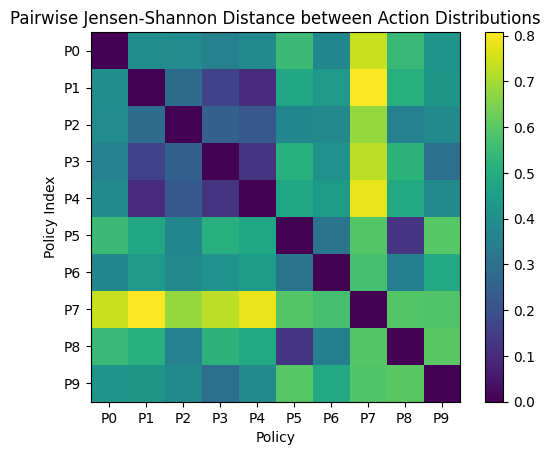

In [17]:
import numpy as np
from scipy.spatial.distance import jensenshannon

def actions_to_distribution(arr, n_actions=None):
    if n_actions is None:
        n_actions = arr.max() + 1
    counts = np.bincount(arr, minlength=n_actions)
    return counts / counts.sum()

n_actions = 8
distributions = [actions_to_distribution(a, n_actions) for a in action_list]

N = len(distributions)
js_matrix = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        js_matrix[i, j] = jensenshannon(distributions[i], distributions[j])

plt.imshow(js_matrix, cmap='viridis')
plt.xticks(ticks=range(len(distributions)), labels=[f'P{i}' for i in range(len(distributions))])
plt.yticks(ticks=range(len(distributions)), labels=[f'P{i}' for i in range(len(distributions))])
plt.xlabel('Policy')
plt.ylabel('Policy Index')
plt.title('Pairwise Jensen-Shannon Distance between Action Distributions')
plt.colorbar()
plt.show()

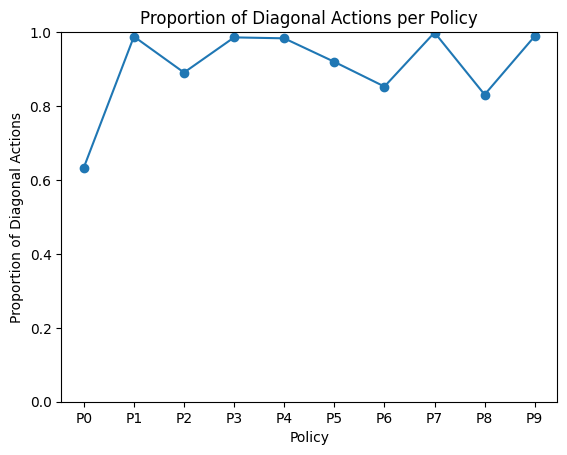

In [18]:
# count diagonal actions (1,3,5,7)
diagonal_action_counts = []
for actions in action_list:
    count = np.sum(np.isin(actions, [1, 3, 5, 7]))
    diagonal_action_counts.append(count/len(actions))

plt.plot(range(len(diagonal_action_counts)), diagonal_action_counts, marker='o')
plt.xticks(ticks=range(len(diagonal_action_counts)), labels=[f'P{i}' for i in range(len(diagonal_action_counts))])
plt.xlabel('Policy')
plt.ylabel('Proportion of Diagonal Actions')
plt.title('Proportion of Diagonal Actions per Policy')
plt.ylim(0, 1)
plt.show()

In [41]:
# load the dataset
import pandas as pd
load = True
if load:
    dfbm = pd.read_csv("benchmark_results_bd.csv")

In [42]:
dfbm

,seed,sim_seed,n_special,beta,delta,pop,pod,rew_mean,lastr_mean
0,0,0,5,3.5,0.3,0.734811,0.260000,-1.031940,-0.897315
1,0,1,5,3.5,0.4,0.618158,0.333333,-1.186355,-1.172184
2,0,2,5,3.5,0.5,0.604989,0.166667,-1.176861,-1.189988
3,0,3,5,3.5,0.6,0.605549,0.160000,-1.196685,-1.166473
4,0,4,5,3.5,0.7,0.572753,0.100000,-1.238259,-1.267812
...,...,...,...,...,...,...,...,...,...
2095,9,37,60,9.5,0.4,0.997331,0.993333,-0.101342,-0.004294
2096,9,38,60,9.5,0.5,0.999994,1.000000,-0.036131,-0.000047
2097,9,39,60,9.5,0.6,0.999961,1.000000,-0.062979,-0.000812
2098,9,40,60,9.5,0.7,0.999921,1.000000,-0.077683,-0.013517


In [43]:
# average over n_special with standard deviation and skip the seeds column
dfbm30 = dfbm[dfbm['n_special'] == 30]
df=dfbm30.groupby(['seed']).agg(['mean', 'std']).drop(columns=['sim_seed', 'n_special', 'beta', 'delta'])
df.style.format("{:.2f}")

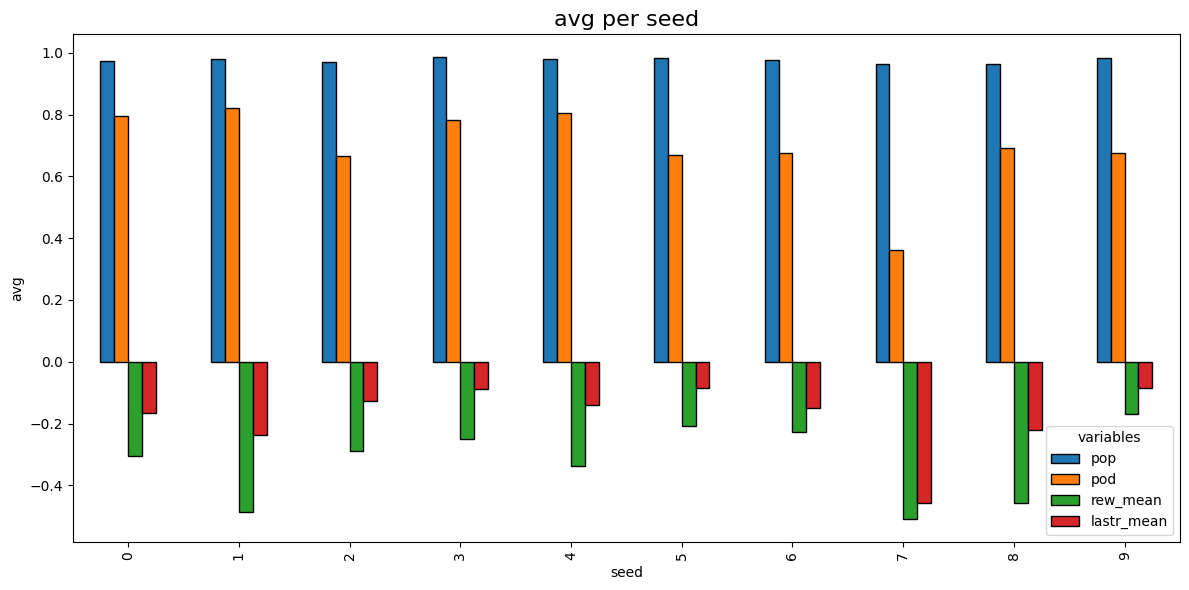

In [44]:
df_means = df.xs('mean', axis=1, level=1)
ax = df_means.plot(kind='bar', figsize=(12, 6), edgecolor='black')

ax.set_title("avg per seed", fontsize=16)
ax.set_xlabel("seed")
ax.set_ylabel("avg")
ax.legend(title="variables")

plt.tight_layout()
plt.show()

In [45]:
def typical_state_policy(trial_state, d):
    s = torch.tensor(trial_state, dtype=torch.float32)
    value_list = []
    action_list = []
    for saving_folder in ['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']:
        ppo_ants.setup_networks()
        ppo_ants.load_weights(saving_folder + '/weights')
        ppo_ants.critic.eval()
        ppo_ants.actor.eval()
        v = ppo_ants.critic(s).detach().numpy()
        a = F.softmax(ppo_ants.actor(s).detach(), dim=1).numpy()
        value_list.append(v)
        action_list.append(a)

    # visualize the average action distribution and value
    plt.imshow(trial_state[0,0], cmap='YlGnBu')
    for i in range(8):
        x = env.directions[i, 0] + 4
        y = env.directions[i, 1] + 4
        plt.text(y, x, f"{np.mean(np.array(action_list), axis=0)[0,i]:.2f}", fontsize=8, ha='center', va='center', color='red')
        
    plt.arrow(4, 4, d[1]/5, d[0]/5, head_width=0.3, head_length=0.3, fc='white', ec='white')
        
    plt.title(f'average value: {np.mean(np.array(value_list), axis=0)[0,0]:.2f}')
    plt.show()

In [46]:
trial_state = np.zeros((1,4,9,9))
for i in range(9):
    for j in range(9):
        if i == j:
            trial_state[0,0,i,8-j] = 30
            trial_state[0,1,i,8-j] = 5

d = [-1,1] 
trial_state[0,3,1+d[0],1+d[1]] = 1

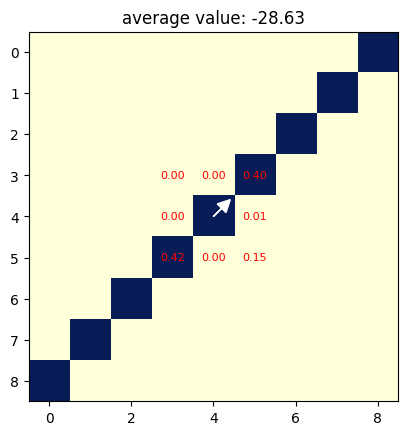

In [47]:
typical_state_policy(trial_state, d)

In [48]:
trial_state = np.zeros((1,4,9,9))
for i in range(9):
    for j in range(9):
        if i == j and i!=5 and i!=6:
            trial_state[0,0,i,j] = 30
            trial_state[0,1,i,j] = 5

d = [-1,-1] 
trial_state[0,3,1+d[0],1+d[1]] = 1

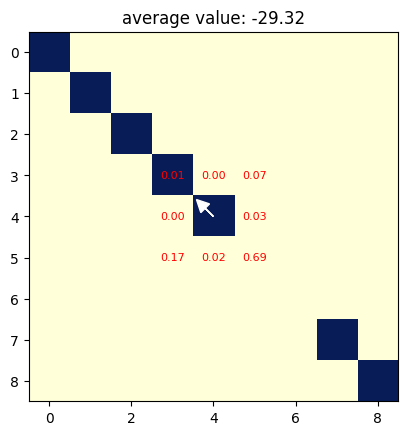

In [49]:
typical_state_policy(trial_state, d)

In [50]:
trial_state = np.zeros((1,4,9,9))
ll = 5
for i in range(9):
    if i<4 or i>4:
        pass
    else:
        trial_state[0,0,i,:ll] = np.ones(ll)*30
        trial_state[0,1,i,:ll] = np.ones(ll)*5
        
        trial_state[0,0,i,ll+2:] = np.ones(9-ll-2)*30
        trial_state[0,1,i,ll+2:] = np.ones(9-ll-2)*5
        
d = [0,1] 
trial_state[0,3,1+d[0],1+d[1]] = 1

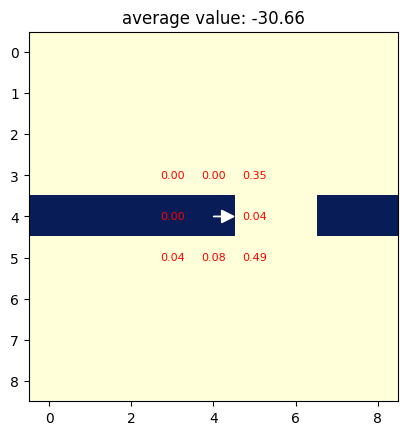

In [51]:
typical_state_policy(trial_state, d)

In [52]:
trial_state = np.zeros((1,4,9,9))
trial_state[0,0] = np.random.uniform(0,10,(9,9))
trial_state[0,1] = np.random.randint(0,1,(9,9))
d = [0,1] 
trial_state[0,3,4+d[0],4+d[1]] = 1

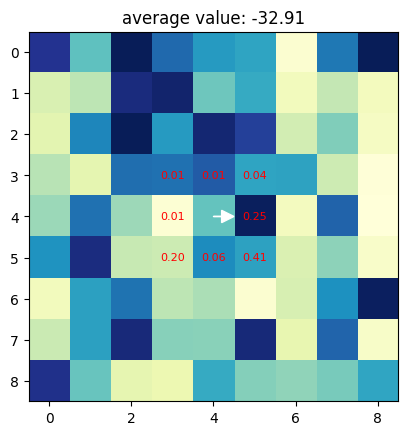

In [53]:
typical_state_policy(trial_state, d)

In [54]:
trial_state = np.zeros((1,4,9,9))
ll = 9
for i in range(9):
    if i<4 or i>4:
        pass
    else:
        trial_state[0,0,:ll,i] = np.ones(ll)*10
        trial_state[0,1,:ll,i] = np.ones(ll)*1
        
d = [1,0] 
trial_state[0,3,4+d[0],4+d[1]] = 1

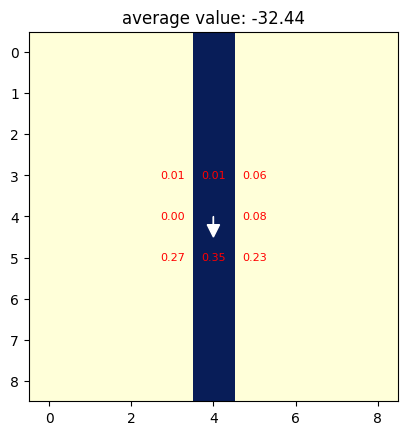

In [55]:
typical_state_policy(trial_state, d)

In [57]:
saving_folder

'l9'

In [ ]:
ppo_ants.env.reset_objects()
ppo_ants.env.transient()

results = ppo_ants.test_episode(max_prob=False, save_pos = True)

In [59]:
rewards = np.array(results[0])
actions = np.array(results[1])
states = np.array(results[2])
pos = np.array(results[3])
pher = np.array(results[4])

/tmp/ipykernel_26081/4068522254.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  states = np.array(results[2])


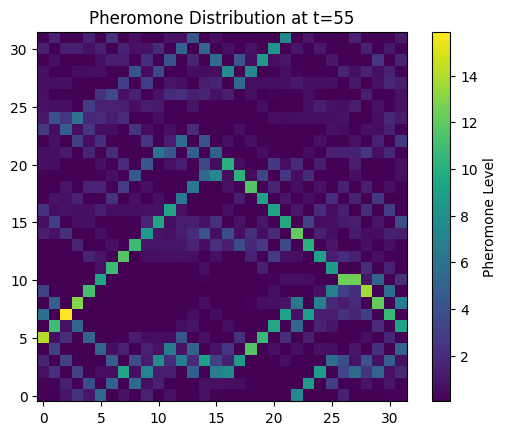

In [111]:
t = np.min(np.where(rewards.mean(axis=1) > -0.5))
plt.imshow(pher[t], cmap='viridis', origin='lower')
plt.colorbar(label='Pheromone Level')
plt.title(f'Pheromone Distribution at t={t}')
plt.show()

(array([  2., 700., 323., 599.,   3.,   9.,   4.,  10.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5]),
 <BarContainer object of 8 artists>)

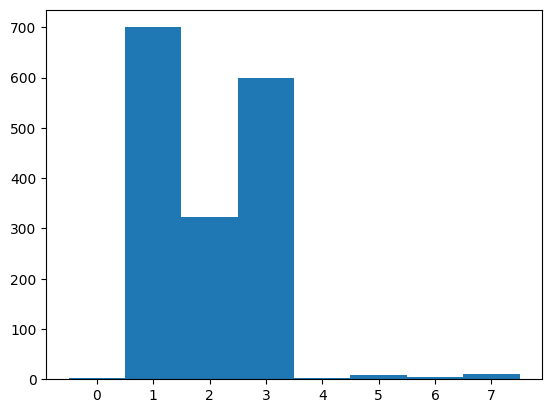

In [114]:
act = actions.reshape(1000,30)
plt.hist(act[:t,:].flatten(), bins=np.arange(-0.5,8.5,1))

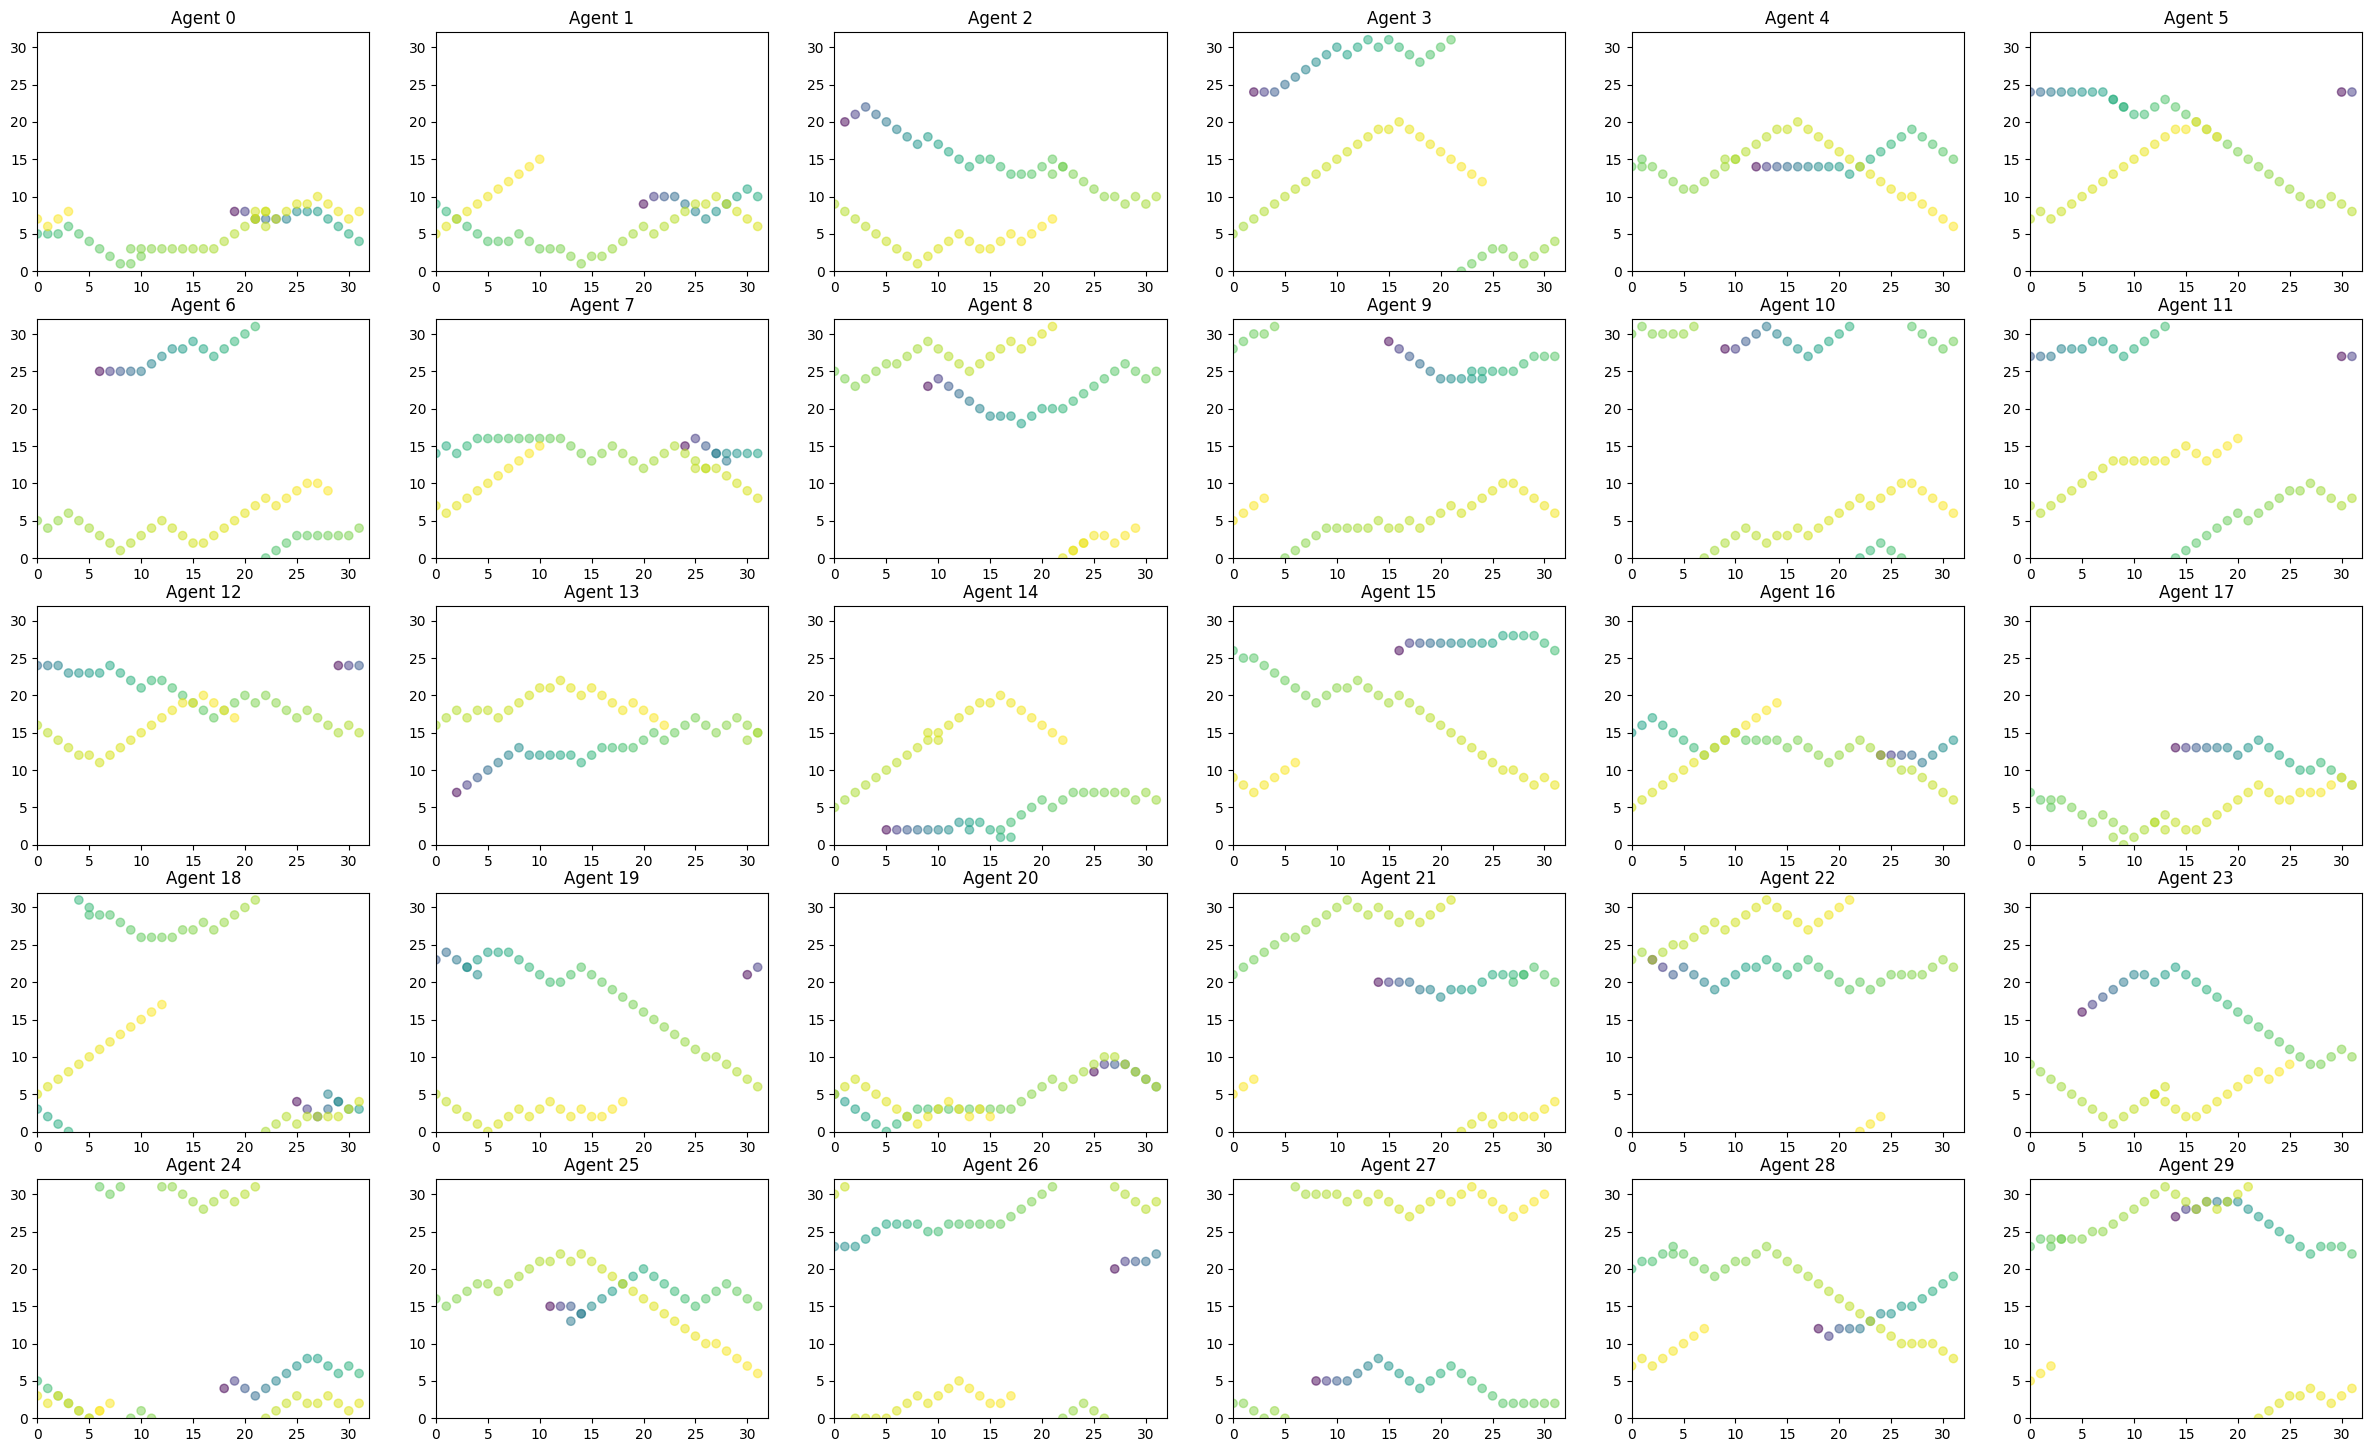

In [110]:
fig, ax = plt.subplots(5, 6, figsize=(30, 18))
data = pos[:t]

for i in range(5):
    for j in range(6):
        ind = i*6 + j
        ax[i,j].set_title(f"Agent {ind}")
        ax[i,j].scatter(data[:,env.n+ind,1], data[:,env.n+ind,0], c=np.log(np.arange(1, t+1)), alpha=0.5)
        ax[i,j].set_ylim(0, Ly)
        ax[i,j].set_xlim(0, Lx)

plt.show()